Authors: 
- Cezary Suchorski 160310
- Bartosz Tarnachowicz 160304

Code repo: https://github.com/csuchorski/evolutionary_computation


# Hamiltonian cycle through a selected half of the nodes

**Evolutionary Computation · Laboratory 1**

This notebook is the report. The optimisation engine is written in C++ (`src/main.cpp`); it reads the instances, builds the distance matrix once and writes machine-readable results (`results/*.csv`). Everything shown below — tables, distributions, 2-D visualisations, best-tour listings and the discussion — is produced here in Python from those files.

| | |
|---|---|
| Instances | `TSPA.csv`, `TSPB.csv` — 200 nodes each |
| Selected nodes | *k* = ⌈*n*/2⌉ = 100 |
| Solutions | 200 random, and 200 per greedy method (one start per node) |
| Seed | 12345 |


## 1. Problem description

Each instance describes **n = 200** points in the plane. Point *i* has coordinates (*x<sub>i</sub>*, *y<sub>i</sub>*) and an integer cost *c<sub>i</sub>*. We must select exactly **k = ⌈n/2⌉ = 100** nodes and arrange them in one closed tour that visits every selected node exactly once, minimising

<p align="center">
F(T) = &Sigma;<sub>i=0</sub><sup>k&minus;1</sup> [ c<sub>t<sub>i</sub></sub> + d(t<sub>i</sub>, t<sub>i+1</sub>) ],&nbsp;&nbsp;&nbsp; t<sub>k</sub> = t<sub>0</sub>,
</p>

where d(i, j) is the Euclidean distance rounded to the nearest integer.

Both terms matter. A cheap node far from the current route may cost more in travel than it saves, and a geometrically convenient node may be expensive. Because |T| is fixed, the node-cost term is an additive penalty of constant size, so the search is never pushed towards selecting fewer nodes.


## 2. Data and distance matrix

The files contain one row per node with the fields `x;y;cost`. The distance matrix is computed **once, immediately after reading**:

<p align="center">
d(i, j) = round( &radic;( (x<sub>i</sub> &minus; x<sub>j</sub>)<sup>2</sup> + (y<sub>i</sub> &minus; y<sub>j</sub>)<sup>2</sup> ) )
</p>

with `std::llround` (half away from zero). The optimisation routines receive only `d[][]` and `cost[]`; the coordinates are used by this notebook for plotting only.

The matrix is stored as **directed arcs** and no symmetry is assumed anywhere. Both supplied instances are Euclidean, hence d(i, j) = d(j, i), but the algorithms never rely on that property.


## 3. Algorithms

Each method constructs a sequence `T` of exactly `k` distinct nodes. Candidates are always ranked by their effect on the complete objective, never by distance alone.

**Notation.** `s` is the starting node, `cost[j]` is the cost of node `j`, `d[a][b]` is the distance from `a` to `b`, and `used[j]` says whether node `j` is already in `T`. The objective is evaluated only after construction:

<p align="center">
F(T) = Σ<sub>v ∈ T</sub> cost[v] + Σ<sub>i = 0</sub><sup>|T|−1</sup> d(T[i], T[(i+1) mod |T|]).
</p>

Ties are resolved deterministically by the smallest node index and then by the earliest insertion position.

### 3.1 Random solution

Choose `k` distinct nodes and visit them in a uniformly random order; there is no greedy scoring.

```text
RANDOM(n, k):
    T ← k distinct nodes chosen uniformly from {0, …, n−1}
    SHUFFLE(T)
    return T
```

For the experiment this constructor is called 200 times.

### 3.2 Nearest neighbour, appending only at the end

The path has a single growing point: its last node. Each step adds the unused node with the smallest increase in the objective.

```text
NN_APPEND(s, k):
    T ← [s]
    mark s as used
    while |T| < k:
        j* ← argmin ( cost[j] + d[T[last]][j] ) over unused j
        append j* to T
        mark j* as used
    return T
```

Only the forward arc `T[last] → j*` is added during construction. The closing arc `T[last] → T[0]` is part of `F(T)` and is added when the tour is evaluated.

### 3.3 Nearest neighbour, best of all positions

A new node may enter at the front, between two consecutive nodes, or at the end. For each unused node and each position, the exact change in the objective is:

```text
INSERTION_DELTA(j, p):
    if p = 0:          return cost[j] + d[j][T[0]]
    if p = |T|:        return cost[j] + d[T[last]][j]
    a ← T[p−1];  b ← T[p]
    return cost[j] + d[a][j] + d[j][b] − d[a][b]
```

The constructor then takes the best `(node, position)` pair:

```text
NN_ANY_POSITION(s, k):
    T ← [s]
    mark s as used
    while |T| < k:
        (j*, p*) ← argmin INSERTION_DELTA(j, p)
                    over unused j and p = 0, …, |T|
        insert j* at position p*
        mark j* as used
    return T
```

Inserting at the front adds only `j → T[0]`; appending adds only `T[last] → j`; an interior insertion replaces one arc `a → b` by `a → j` and `j → b`.

### 3.4 Greedy cycle

The cycle is closed after every insertion. A new node is placed into an existing edge `a → b`, so the old arc is removed and two new arcs are added.

```text
CYCLE_DELTA(a, b, j):
    return cost[j] + d[a][j] + d[j][b] − d[a][b]

GREEDY_CYCLE(s, k):
    j* ← argmin ( cost[j] + d[s][j] + d[j][s] ) over j ≠ s
    T ← [s, j*]                         # two-node cycle s → j* → s
    mark s and j* as used
    while |T| < k:
        best ← +∞
        for each unused j:
            for each edge a → b of T:   # includes the wrap edge last → first
                Δ ← CYCLE_DELTA(a, b, j)
                if Δ < best:
                    best ← Δ;  (j*, a*) ← (j, a)
        insert j* immediately after a*
        mark j* as used
    return T
```

The wrap edge is treated like any other edge. Inserting at the end therefore costs

<p align="center">cost[j] + d[last][j] + d[j][first] − d[last][first],</p>

not merely `cost[j] + d[last][j]`: the return arc is added and the previous closing arc is removed.

Because every method simply builds `T`, the same `EVALUATE(T)` routine computes the distance, node costs and objective for all 200 runs of every method.


In [1]:
%matplotlib inline
from pathlib import Path
import subprocess

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "main.cpp").exists():
    ROOT = ROOT.parent
RES = ROOT / "results"
FIG = ROOT / "report" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

SEED, RUNS = 12345, 200

build = subprocess.run(["make", "-C", str(ROOT)], capture_output=True, text=True)
if build.returncode != 0:
    print(build.stdout + build.stderr)
    raise RuntimeError("build failed")

proc = subprocess.run(
    [str(ROOT / "tsp_solver"),
     "--seed", str(SEED), "--runs", str(RUNS), "--out", "results"],
    cwd=ROOT, capture_output=True, text=True)
print(proc.stdout.strip())
if proc.returncode != 0:
    print(proc.stderr)
    raise RuntimeError("solver failed")

mpl.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 200,
    "font.size": 8,
    "axes.titlesize": 8.5,
    "axes.labelsize": 8,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
})
print(f"\nPython {__import__('sys').version.split()[0]} · "
      f"pandas {pd.__version__} · matplotlib {mpl.__version__}")

Instance TSPA: n = 200, k = 100
  Random                       min 235605   max 292306   avg 261429.4    (0.4 ms)
  Nearest neighbour (append at end) min 84362    max 90075    avg 87476.6     (5.0 ms)
  Nearest neighbour (any position) min 72328    max 77022    avg 74347.0     (242.8 ms)
  Greedy cycle                 min 72590    max 75281    avg 73793.4     (359.6 ms)
Instance TSPB: n = 200, k = 100
  Random                       min 183300   max 229903   avg 207269.3    (0.3 ms)
  Nearest neighbour (append at end) min 56007    max 63166    avg 59397.3     (4.9 ms)
  Nearest neighbour (any position) min 52915    max 66164    avg 59475.5     (241.2 ms)
  Greedy cycle                 min 55655    max 63734    avg 59649.9     (355.7 ms)

Results written to results/
  summary.csv, runs.csv, best_tours.csv, best_tours_columns.csv

Python 3.14.8 · pandas 3.0.6 · matplotlib 3.11.2


In [2]:
summary = pd.read_csv(RES / "summary.csv")
runs = pd.read_csv(RES / "runs.csv")
tours = pd.read_csv(RES / "best_tours.csv")
INSTANCES = list(dict.fromkeys(summary["instance"]))
COORDS = {name: pd.read_csv(ROOT / f"{name}.csv", sep=";", header=None,
                            names=["x", "y", "cost"])
          for name in INSTANCES}
COST_RANGE = {n: (int(d.cost.min()), int(d.cost.max())) for n, d in COORDS.items()}

LABELS = {
    "random": "Random",
    "nn_end": "NN (append at end)",
    "nn_all": "NN (any position)",
    "greedy_cycle": "Greedy cycle",
}
METHODS = list(LABELS)
SHORT = {
    "random": "Random",
    "nn_end": "NN append",
    "nn_all": "NN any pos.",
    "greedy_cycle": "Greedy cycle",
}
COLORS = {"random": "#9aa0a6", "nn_end": "#4c72b0",
          "nn_all": "#dd8452", "greedy_cycle": "#55a868"}

In [3]:
def nf(v):
    return f"{int(v):,}"

def f1(v):
    return f"{v:,.1f}"

meta_disp = pd.DataFrame([{
    "Instance": name,
    "File": f"{name}.csv",
    "n": len(COORDS[name]),
    "k": (len(COORDS[name]) + 1) // 2,
    "Min cost": COST_RANGE[name][0],
    "Max cost": COST_RANGE[name][1],
} for name in INSTANCES])
display(meta_disp.style.format({
    "Min cost": "{:,.0f}", "Max cost": "{:,.0f}"}))

,Instance,File,n,k,Min cost,Max cost
0,TSPA,TSPA.csv,200,100,0,"1,997"
1,TSPB,TSPB.csv,200,100,3,999


## 4. Computational experiment

For every instance, 200 random solutions were generated and each greedy method was run 200 times. With n = 200 and 200 runs, run *r* starts from node *r*, so every node is used exactly once as a starting point. The random generator is `std::mt19937` seeded with 12345, which makes the results reproducible. All runs are independent; no solution is improved after construction. The engine is compiled with `g++ -O2 -std=c++17`.

## 5. Results

The table gives the minimum, maximum and average objective over the 200 constructions, with the two instances side by side.

In [4]:
summary_disp = summary.pivot(
    index="method", columns="instance", values=["min", "max", "average"]
).reindex(METHODS)
summary_disp.index = [SHORT[m] for m in summary_disp.index]
summary_disp = summary_disp.swaplevel(0, 1, axis=1).reindex(
    columns=pd.MultiIndex.from_product([INSTANCES, ["min", "max", "average"]]))
summary_disp.columns = summary_disp.columns.set_names(["Instance", "Statistic"])
summary_disp = summary_disp.rename(
    columns={"min": "Min", "max": "Max", "average": "Average"}, level=1)

sty = summary_disp.style.format(
    "{:,.0f}", subset=[(name, stat) for name in INSTANCES for stat in ("Min", "Max")]
).format("{:,.1f}", subset=[(name, "Average") for name in INSTANCES])
display(sty)

*NN = nearest neighbour; "append" inserts only at the end of the path, "any pos." at the front, inside or at the end.*

The minimum, maximum and average are the required statistics; the box plots below show the whole distribution of the 200 solutions per method. White diamonds mark the means, horizontal lines the medians.

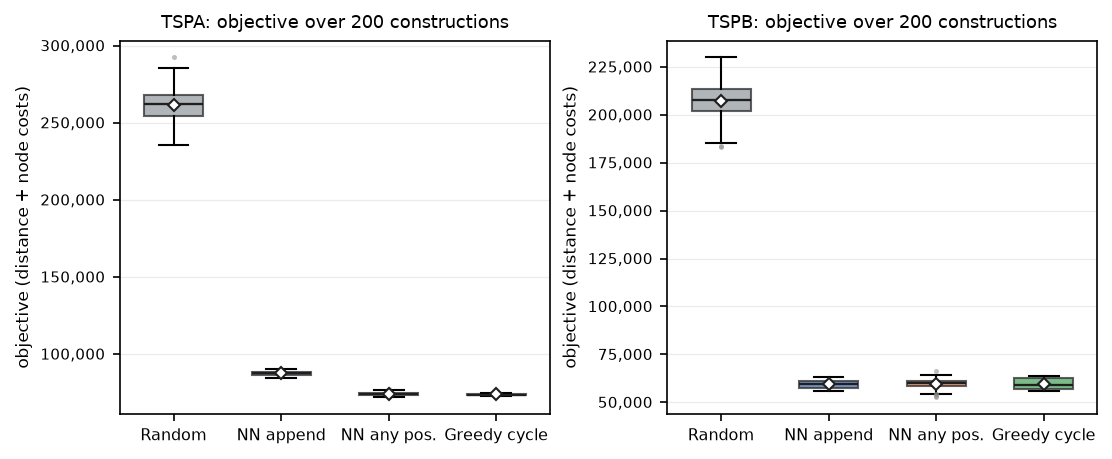

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(7.3, 2.95), layout="constrained")

for ax, (name, grp) in zip(axes, runs.groupby("instance", sort=False)):
    data = [grp.loc[grp.method == m, "objective"].to_numpy() for m in METHODS]
    bp = ax.boxplot(
        data, tick_labels=[SHORT[m] for m in METHODS], widths=0.55,
        patch_artist=True, showmeans=True,
        medianprops=dict(color="#1f1f1f", lw=1.1),
        meanprops=dict(marker="D", markerfacecolor="white",
                       markeredgecolor="#1f1f1f", markersize=4),
        flierprops=dict(marker="o", markersize=2.4, markerfacecolor="#8a8a8a",
                        markeredgecolor="none", alpha=0.55),
    )
    for patch, m in zip(bp["boxes"], METHODS):
        patch.set_facecolor(COLORS[m])
        patch.set_alpha(0.78)
        patch.set_edgecolor("#333333")
    ax.set_title(f"{name}: objective over {RUNS} constructions", fontsize=8.5)
    ax.set_ylabel("objective (distance + node costs)", fontsize=8)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{int(v):,}"))
    ax.grid(axis="y", alpha=0.25, lw=0.6)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", labelsize=7.5)
    ax.tick_params(axis="y", labelsize=7)

fig.savefig(FIG / "distributions.png", bbox_inches="tight")
plt.show()

Random construction is far behind the greedy methods and has the widest spread. Among the greedy methods the differences are much smaller, so the choice of insertion rule matters more than the starting node.

## 6. Best solutions

Each panel shows the cycle built by one method. Grey dots are nodes that were **not** selected. Selected nodes are drawn with a colour **and** a radius that both encode the node cost (dark purple, small = cheap; yellow, large = expensive). Thin arrows show the direction of travel along the cycle.

In [6]:
CMAP = plt.get_cmap("viridis")

def load_tour(name, method):
    row = tours[(tours.instance == name) & (tours.method == method)].iloc[0]
    return np.array([int(v) for v in str(row["tour"]).split()]), row

def draw(ax, name, method, norm):
    df = COORDS[name]
    tour, row = load_tour(name, method)
    sel = np.zeros(len(df), dtype=bool)
    sel[tour] = True
    x = df.x.to_numpy()
    y = df.y.to_numpy()
    cost = df.cost.to_numpy()

    ax.scatter(x[~sel], y[~sel], s=5, c="#d4d4d4", linewidths=0, zorder=1)
    for i in range(len(tour)):
        a, b = tour[i], tour[(i + 1) % len(tour)]
        ax.annotate("", xy=(x[b], y[b]), xytext=(x[a], y[a]),
                    arrowprops=dict(arrowstyle="-|>", color="#555555", lw=0.42,
                                    shrinkA=2.0, shrinkB=3.0, mutation_scale=5,
                                    alpha=0.75),
                    zorder=2)
    t = (cost[tour] - norm.vmin) / max(1e-9, norm.vmax - norm.vmin)
    ax.scatter(x[tour], y[tour], s=7 + 42 * t, c=cost[tour], cmap=CMAP,
               norm=norm, edgecolors="#1b1b1b", linewidths=0.35, zorder=3)

    ax.set_title(f"{LABELS[method]}\nobjective {nf(row['objective'])}",
                 fontsize=7.8, pad=3)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_color("#dcdcdc")

def best_figure(name):
    norm = mpl.colors.Normalize(*COST_RANGE[name])
    fig, axes = plt.subplots(2, 2, figsize=(7.3, 5.0), layout="constrained")
    for ax, method in zip(axes.ravel(), METHODS):
        draw(ax, name, method, norm)
    fig.suptitle(f"{name}: best solution found by each method", fontsize=10)
    sm = mpl.cm.ScalarMappable(norm=norm, cmap=CMAP)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=axes.ravel().tolist(), fraction=0.022, pad=0.015)
    cb.set_label("node cost", fontsize=7.5)
    cb.ax.tick_params(labelsize=6.5)
    fig.savefig(FIG / f"best_{name}.png", bbox_inches="tight")
    plt.show()

    for method in METHODS:
        single, ax = plt.subplots(figsize=(7.3, 4.4), layout="constrained")
        draw(ax, name, method, norm)
        single.savefig(FIG / f"best_{name}_{method}.png", bbox_inches="tight")
        plt.close(single)

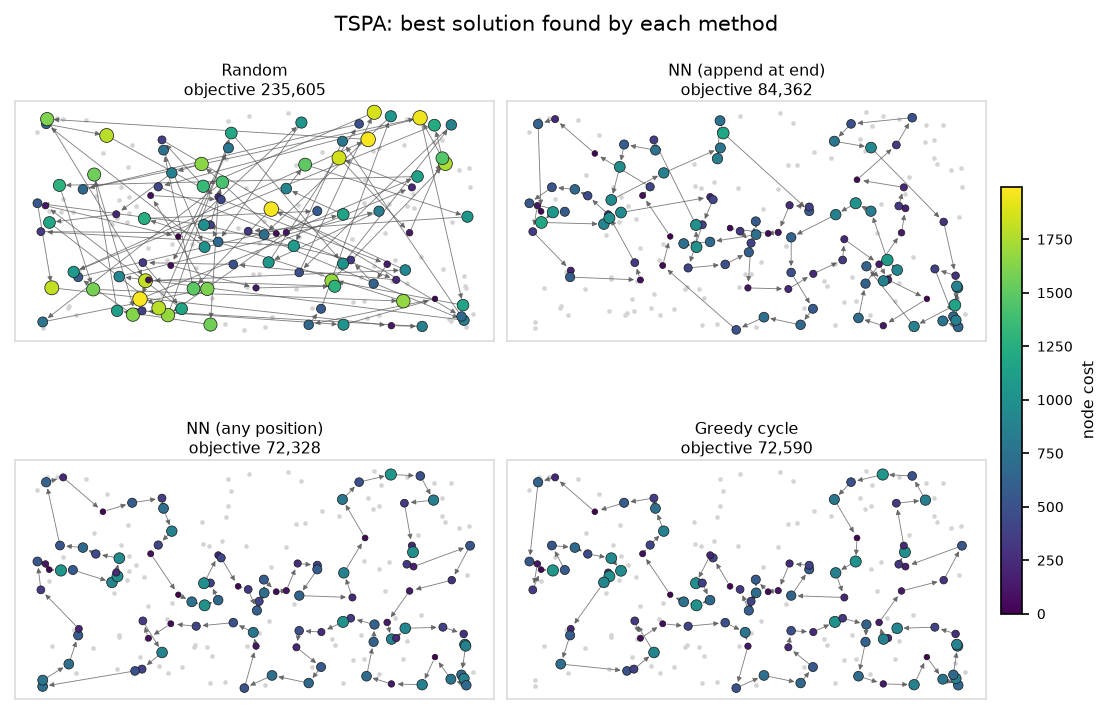

In [7]:
best_figure("TSPA")

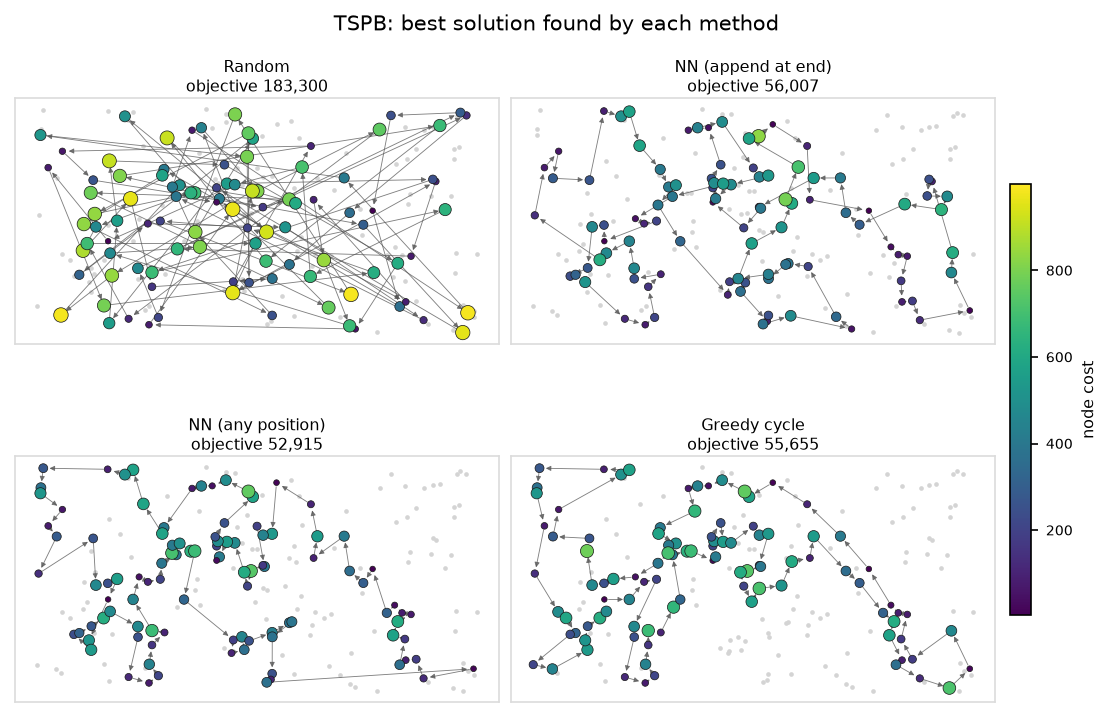

In [8]:
best_figure("TSPB")

## 7. Best solutions as node lists

All indices are **0-based**; the list is the cycle order and the closing arc runs from the last node back to the first one. For spreadsheet use, `results/best_tours_columns.csv` stores the same eight tours as columns: every column contains 100 node indices, one per row, so it can be copied directly into Excel without reformatting.

The best solutions have been checked with the Excel solution checker.

In [9]:
for name in INSTANCES:
    print(name)
    for method in METHODS:
        _, row = load_tour(name, method)
        idx = str(row["tour"]).split()
        print(f"\n{LABELS[method]} — objective {nf(row['objective'])} "
              f"(distance {nf(row['distance'])}, costs {nf(row['costs'])}), "
              f"first node {int(row['first_node'])}:")
        for i in range(0, len(idx), 16):
            print("  " + " ".join(idx[i:i + 16]))
    print()

TSPA

Random — objective 235,605 (distance 143,298, costs 92,307), first node 40:
  40 113 74 96 71 102 31 137 51 22 92 66 171 32 127 194
  143 15 37 144 193 161 85 41 136 108 29 75 13 155 79 76
  89 45 30 10 149 180 154 185 35 133 129 70 132 16 106 151
  176 156 116 188 57 64 2 111 107 192 158 163 179 36 59 82
  120 124 162 54 183 5 72 55 84 197 196 157 153 186 99 168
  177 18 4 123 119 166 112 141 135 65 187 198 1 109 93 46
  17 95 195 199

NN (append at end) — objective 84,362 (distance 31,319, costs 53,043), first node 54:
  54 9 33 36 177 67 144 53 135 58 134 176 174 106 89 107
  57 182 151 93 50 3 1 164 178 29 136 186 184 47 159 130
  153 78 88 193 170 146 75 64 150 42 113 43 85 142 8 131
  84 158 192 181 114 141 180 132 76 80 48 31 63 149 168 97
  127 187 30 123 152 108 60 116 49 11 119 160 83 90 51 16
  35 87 45 140 52 179 185 28 102 156 157 71 91 38 100 4
  112 139 115 5

NN (any position) — objective 72,328 (distance 21,816, costs 50,512), first node 104:
  104 129 69 127 97 

## 8. Observations

In [10]:
import textwrap

from IPython.display import Markdown

stats = runs.groupby(["instance", "method"]).agg(
    mean=("objective", "mean"),
    std=("objective", "std"),
    dist=("distance", "mean"),
    cost=("costs", "mean"),
).reset_index()
stats["cv"] = 100.0 * stats["std"] / stats["mean"]

def get_stat(name, method, column):
    row = stats[(stats.instance == name) & (stats.method == method)]
    return row.iloc[0][column]

def get_summary(name, method):
    row = summary[(summary.instance == name) & (summary.method == method)]
    return row.iloc[0]

def best_row(name):
    sub = summary[summary.instance == name]
    return sub.loc[sub["best"].idxmin()]

def start_wins(name):
    p = runs[(runs.instance == name) & (runs.method != "random")].pivot(
        index="start_node", columns="method", values="objective")
    return p.idxmin(axis=1).value_counts()

def pct_change(a, b):
    return 100.0 * (b - a) / a

def pct_range(values, decimals=1):
    return f"{min(values):.{decimals}f}–{max(values):.{decimals}f}%"

def nr(value):
    return f"{round(value):,}"

def cv_range(name):
    values = stats[(stats.instance == name) & (stats.method != "random")]["cv"]
    return pct_range(values, 1)

items = []

items.append(
    "No method wins both instances on average. The lowest average objective in the experiment "
    "is produced by append-at-end on TSPB, while greedy cycle is best on TSPA; the "
    "margins over the next method are only "
    f"{abs(pct_change(get_stat('TSPA', 'nn_all', 'mean'), get_stat('TSPA', 'greedy_cycle', 'mean'))):.1f}% "
    f"and {abs(pct_change(get_stat('TSPB', 'nn_all', 'mean'), get_stat('TSPB', 'nn_end', 'mean'))):.1f}%. "
    "Absolute objective values should not be compared between instances because "
    "their node-cost scales differ."
)

a_g = get_summary("TSPA", "greedy_cycle")
a_all = get_summary("TSPA", "nn_all")
a_gd = get_stat("TSPA", "greedy_cycle", "dist")
a_ad = get_stat("TSPA", "nn_all", "dist")
a_gc = get_stat("TSPA", "greedy_cycle", "cost")
a_ac = get_stat("TSPA", "nn_all", "cost")
a_wins = start_wins("TSPA")
items.append(
    "TSPA is the clearest result. Greedy cycle beats NN any-position on "
    f"{a_wins.get('greedy_cycle', 0)}/{RUNS} starts and beats append-at-end on "
    f"{RUNS - a_wins.get('nn_end', 0)}/{RUNS}. Its mean route is "
    f"{-pct_change(a_ad, a_gd):.1f}% shorter than NN any-position "
    f"({nr(a_gd)} vs {nr(a_ad)}), while its mean node cost is only "
    f"{pct_change(a_ac, a_gc):.1f}% higher ({nr(a_gc)} vs {nr(a_ac)}). The gain "
    "therefore comes from route quality, not cheaper nodes. Greedy cycle also has "
    f"the smallest relative spread on TSPA ({get_stat('TSPA', 'greedy_cycle', 'cv'):.1f}%)."
)

b_end = get_summary("TSPB", "nn_end")
b_all = get_summary("TSPB", "nn_all")
b_g = get_summary("TSPB", "greedy_cycle")
b_ed = get_stat("TSPB", "nn_end", "dist")
b_ad = get_stat("TSPB", "nn_all", "dist")
b_gd = get_stat("TSPB", "greedy_cycle", "dist")
b_ec = get_stat("TSPB", "nn_end", "cost")
b_ac = get_stat("TSPB", "nn_all", "cost")
b_gc = get_stat("TSPB", "greedy_cycle", "cost")
b_em = get_stat("TSPB", "nn_end", "mean")
b_am = get_stat("TSPB", "nn_all", "mean")
b_gm = get_stat("TSPB", "greedy_cycle", "mean")
b_wins = start_wins("TSPB")
b_win_counts = [int(b_wins.get(m, 0)) for m in ("nn_end", "nn_all", "greedy_cycle")]
b_dist_pen = [pct_change(b_ad, b_ed), pct_change(b_gd, b_ed)]
b_cost_gain = [-pct_change(b_ac, b_ec), -pct_change(b_gc, b_ec)]
items.append(
    "TSPB reverses the trade-off. Append-at-end is only "
    f"{-pct_change(b_am, b_em):.1f}% better than NN any-position and "
    f"{-pct_change(b_gm, b_em):.1f}% better than greedy on average. It achieves "
    f"this by accepting a {pct_range(b_dist_pen, 0)} longer mean route "
    f"({nr(b_ed)} vs {nr(b_ad)}/{nr(b_gd)}) in exchange for a "
    f"{pct_range(b_cost_gain, 0)} lower mean node cost "
    f"({nr(b_ec)} vs {nr(b_ac)}/{nr(b_gc)}). The three methods win "
    f"{min(b_win_counts)}–{max(b_win_counts)} of {RUNS} starts, so the ranking is "
    f"weak; TSPB is also much more start-sensitive (CV {cv_range('TSPB')} vs "
    f"{cv_range('TSPA')} on TSPA)."
)

a_best = best_row("TSPA")
b_best = best_row("TSPB")
b_end_best = get_summary("TSPB", "nn_end")["best"]
items.append(
    f"Best-of-200 is a different criterion: {LABELS[a_best['method']]} produces the "
    f"best single solution on TSPA ({nf(a_best['best'])}) and the same method also "
    f"produces the best single TSPB tour ({nf(b_best['best'])}), which is the global "
    f"best. On TSPB it is {abs(pct_change(b_end_best, b_best['best'])):.1f}% below "
    "append-at-end's best tour, so the broader positional search has the best upside "
    "but also the higher variance; it is preferable when one good solution matters, "
    "while greedy cycle on TSPA and append-at-end on TSPB are preferable for average "
    "reliability."
)

k_cost = {name: (len(COORDS[name]) + 1) // 2 for name in INSTANCES}
floor = {
    name: int(COORDS[name].cost.nsmallest(k_cost[name]).sum())
    for name in INSTANCES
}
a_floor_gap = pct_change(floor["TSPA"], a_gc)
b_floor_gap = pct_change(floor["TSPB"], b_ec)
b_floor_gap_all = pct_change(floor["TSPB"], b_ac)
b_floor_gap_g = pct_change(floor["TSPB"], b_gc)
items.append(
    "The leading TSPA methods are already close to the cheapest-100 node-cost "
    f"floor: greedy averages {nr(a_gc)} against {nf(floor['TSPA'])} "
    f"(+{a_floor_gap:.1f}%), so further gains must come mainly from travel. On "
    f"TSPB, append-at-end is {nr(b_ec)} against {nf(floor['TSPB'])} "
    f"(+{b_floor_gap:.1f}%), while the insertion methods are "
    f"+{min(b_floor_gap_all, b_floor_gap_g):.0f}–{max(b_floor_gap_all, b_floor_gap_g):.0f}% "
    "above the floor; the TSPB winner is the only method that stays relatively close "
    "to the cheap-node set."
)

ms = summary.groupby("method")["time_ms"].mean() / RUNS
items.append(
    "Runtime grows with the amount of search. Append-at-end needs about "
    f"{ms['nn_end']:.3f} ms per construction, NN any-position {ms['nn_all']:.2f} ms, "
    f"and greedy cycle {ms['greedy_cycle']:.2f} ms. Greedy is roughly "
    f"{ms['greedy_cycle'] / ms['nn_end']:.0f}x slower than append-at-end and "
    f"{ms['greedy_cycle'] / ms['nn_all']:.1f}x slower than NN any-position; that extra "
    "work is justified on TSPA (0.7% better average) but not on TSPB (0.4% worse)."
)

a_rc = get_stat("TSPA", "random", "cost")
b_rc = get_stat("TSPB", "random", "cost")
items.append(
    "Random is a baseline rather than a contender: it is roughly 3.5x worse on "
    f"average, and its node-cost term alone is much higher ({nr(a_rc)} vs {nr(a_gc)} "
    f"on TSPA; {nr(b_rc)} vs {nr(b_ec)} on TSPB), so it fails on both parts of the "
    "objective, not only route length."
)

bullets = "\n".join(
    textwrap.fill(item, width=88, initial_indent="- ", subsequent_indent="  ")
    for item in items
)
display(Markdown(bullets))


- No method wins both instances on average. The lowest average objective in the
  experiment is produced by append-at-end on TSPB, while greedy cycle is best on TSPA;
  the margins over the next method are only 0.7% and 0.1%. Absolute objective values
  should not be compared between instances because their node-cost scales differ.
- TSPA is the clearest result. Greedy cycle beats NN any-position on 144/200 starts and
  beats append-at-end on 200/200. Its mean route is 3.3% shorter than NN any-position
  (22,304 vs 23,071), while its mean node cost is only 0.4% higher (51,489 vs 51,276).
  The gain therefore comes from route quality, not cheaper nodes. Greedy cycle also has
  the smallest relative spread on TSPA (0.7%).
- TSPB reverses the trade-off. Append-at-end is only 0.1% better than NN any-position
  and 0.4% better than greedy on average. It achieves this by accepting a 44–49% longer
  mean route (26,882 vs 18,678/18,015) in exchange for a 20–22% lower mean node cost
  (32,515 vs 40,798/41,635). The three methods win 65–68 of 200 starts, so the ranking
  is weak; TSPB is also much more start-sensitive (CV 3.5–4.7% vs 0.7–1.5% on TSPA).
- Best-of-200 is a different criterion: NN (any position) produces the best single
  solution on TSPA (72,328) and the same method also produces the best single TSPB tour
  (52,915), which is the global best. On TSPB it is 5.5% below append-at-end's best
  tour, so the broader positional search has the best upside but also the higher
  variance; it is preferable when one good solution matters, while greedy cycle on TSPA
  and append-at-end on TSPB are preferable for average reliability.
- The leading TSPA methods are already close to the cheapest-100 node-cost floor: greedy
  averages 51,489 against 49,272 (+4.5%), so further gains must come mainly from travel.
  On TSPB, append-at-end is 32,515 against 27,292 (+19.1%), while the insertion methods
  are +49–53% above the floor; the TSPB winner is the only method that stays relatively
  close to the cheap-node set.
- Runtime grows with the amount of search. Append-at-end needs about 0.025 ms per
  construction, NN any-position 1.21 ms, and greedy cycle 1.79 ms. Greedy is roughly 72x
  slower than append-at-end and 1.5x slower than NN any-position; that extra work is
  justified on TSPA (0.7% better average) but not on TSPB (0.4% worse).
- Random is a baseline rather than a contender: it is roughly 3.5x worse on average, and
  its node-cost term alone is much higher (97,312 vs 51,489 on TSPA; 51,829 vs 32,515 on
  TSPB), so it fails on both parts of the objective, not only route length.

**Discussion.** The two instances reward different heuristics because the balance between travel and node cost is different. On TSPA the leading methods already select similarly cheap node sets, so route length decides; greedy cycle's closed-edge insertion shortens the average route and wins on 144/200 starts, making it the most reliable TSPA method. On TSPB, append-at-end accepts a much longer route in exchange for a substantially lower node-cost bill; the saving almost exactly offsets the extra travel, leaving a margin of only 0.1–0.4%, and the per-start wins are split 65–68, so there is no robust winner.

NN any-position is the best single-shot method: it finds the best individual tour on both instances, including the global best on TSPB, but its higher variance makes it less reliable on average. Runtime reinforces the instance-dependent choice: greedy costs about 1.8 ms per construction versus 1.2 ms for NN any-position and 0.025 ms for append-at-end. The extra computation is worthwhile on TSPA but not on TSPB. The practical recommendation is therefore greedy cycle for TSPA-like instances, append-at-end for TSPB-like instances where cheaper nodes are worth a longer route, and NN any-position when one high-quality solution matters more than average reliability.

## 9. Reproduction

```bash
# 1. Python environment (once)
python3 -m venv .venv
.venv/bin/pip install nbconvert ipykernel matplotlib pandas numpy jupyterlab

# 2. Engine
make

# 3. Execute this notebook, export HTML with report.css and print the PDF
.venv/bin/python tools/render_report.py
```

`run.sh` performs all of these steps and can also be used to rebuild everything from scratch; the notebook can be opened for interactive use with `.venv/bin/jupyter lab`. The engine writes `results/summary.csv`, `results/runs.csv`, `results/best_tours.csv` and `results/best_tours_columns.csv`; this notebook writes the figures to `report/figures/` and the exported report to `report/report.html` and `report/report.pdf`.